In [1]:
import matplotlib.pyplot as plt
from astropy.table import Table
import matplotlib.colors as mpl_colors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

In [3]:
tab_DAP = Table.read('DAPtable_helix.ecsv')
print('\ntab_DAP:\n',tab_DAP)


tab_DAP:
     id            ra         ...  X_sq_pek_9069.0    X_sq_pek_9531.1  
--------- ------------------ ... ------------------ ------------------
   4297.3  337.4169474614286 ... 1.3629693989829357 1.8276064927905626
   4297.4 337.42638153117906 ... 0.8842719614623011 2.1337073864328078
   4297.5 337.43581492731073 ... 1.8172620083840267 3.0613251971594515
   4297.6  337.4452142099591 ...  1.616723763279993 2.0232588773532894
   4297.7 337.45464625878174 ...  7.509199158175764 20.473380194511204
   4297.8 337.46407763267024 ...  1.172444005857491  1.689329535335471
   4297.9 337.47350833118605 ...   1.03862740097424  1.850846503869197
  4297.10 337.48293835389075 ... 2.6111163308880307  12.26815153927675
  4297.11 337.49233426716734 ... 0.9827429216924148 1.3101056605935648
  4297.12    337.50176293819 ... 3.3937517598670857  8.658537721161245
      ...                ... ...                ...                ...
4297.1934  337.2728561387537 ...  2.070920230862537  6.03031484304

## Select column names based on a search string
This helper function can be used to find column names matching a particular line, wavelength, or analysis type.

In [4]:
def search_col(tab,key):
    a_keys=[]
    for keys in tab.columns:
        if (keys.find(key)>-1):
            a_keys.append(keys)
    return a_keys

In [5]:
# In this particular case we search for the [OII] emission line, which is a doublet at 3727.09 and 3729.88 Angstroms
print('Cols with [OII]:', search_col(tab_DAP,'[OII]'))
# The parametric columns do not have [OII] in the column name, so better to search on wavelength
print('\nCols with 372:', search_col(tab_DAP,'372'))
# Columns involving Halpha
print('\nCols with 6562:', search_col(tab_DAP,'_6562'))
# Columns involving stellar analysis
print('\nCols with st:', search_col(tab_DAP,'_st'))

Cols with [OII]: ['flux_[OII]_3726.03', 'flux_[OII]_3728.82', 'vel_[OII]_3726.03', 'vel_[OII]_3728.82', 'disp_[OII]_3726.03', 'disp_[OII]_3728.82', 'EW_[OII]_3726.03', 'EW_[OII]_3728.82', 'e_flux_[OII]_3726.03', 'e_flux_[OII]_3728.82', 'e_vel_[OII]_3726.03', 'e_vel_[OII]_3728.82', 'e_disp_[OII]_3726.03', 'e_disp_[OII]_3728.82', 'e_EW_[OII]_3726.03', 'e_EW_[OII]_3728.82', 'flux_[OII]_7318.92', 'flux_[OII]_7329.66', 'vel_[OII]_7318.92', 'vel_[OII]_7329.66', 'disp_[OII]_7318.92', 'disp_[OII]_7329.66', 'EW_[OII]_7318.92', 'EW_[OII]_7329.66', 'e_flux_[OII]_7318.92', 'e_flux_[OII]_7329.66', 'e_vel_[OII]_7318.92', 'e_vel_[OII]_7329.66', 'e_disp_[OII]_7318.92', 'e_disp_[OII]_7329.66', 'e_EW_[OII]_7318.92', 'e_EW_[OII]_7329.66', 'sigma_kms_[OII]_3726.03', 'sigma_kms_[OII]_3728.82', 'sigma_kms_[OII]_7318.92', 'sigma_kms_[OII]_7329.66', 'X_sq_[OII]_3726.03', 'X_sq_[OII]_3728.82', 'X_sq_[OII]_7318.92', 'X_sq_[OII]_7329.66']

Cols with 372: ['flux_pe_3726.03', 'flux_pe_3728.82', 'e_flux_pe_3726.03'

## Balmer-ratio diagnostic plot

This scatter plot compares `Hα/Hβ` against `Hβ/Hγ` for fibers with strong Hα.  
It is a compact way to inspect recombination and dust content consistency and possible deviations caused by noise, background issues, or residual calibration problems.

The interpretation should remain cautious, especially in low-S/N fibers or in regions where the line measurements are affected by background residuals.

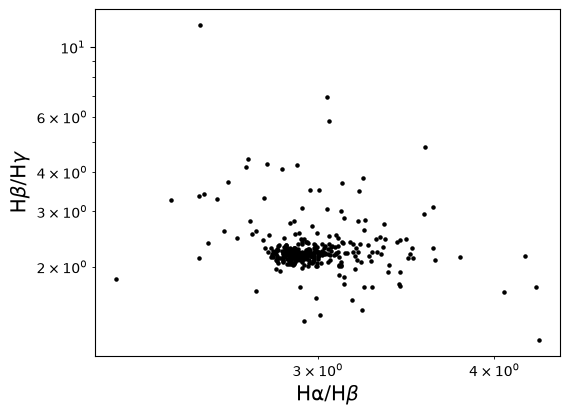

In [6]:
fig, ax = plt.subplots(figsize=(6,4.5))
snrcut = 30
mask_SN_Ha = tab_DAP['flux_pek_6562.85']/tab_DAP['e_flux_pek_6562.85'] > snrcut
ax.scatter((tab_DAP['flux_Halpha_6562.85']/tab_DAP['flux_Hbeta_4861.36'])[mask_SN_Ha],
           (tab_DAP['flux_Hbeta_4861.36']/tab_DAP['flux_Hgamma_4340.49'])[mask_SN_Ha],
           s=5, c='black')
ax.set_xlabel(r'Hα/H$\beta$', fontsize='x-large')
ax.set_ylabel(r'H$\beta$/H$\gamma$', fontsize='x-large')
ax.set_xscale('log')
ax.set_yscale('log')

## Density-sensitive ratio versus line width

This plot compares the Hα velocity dispersion (applying a 10$\sigma$ cut on H$\alpha$ flux) with the `[S II] 6716/6731` ratio, which is a classical electron-density diagnostic.

The idea is not that a one-to-one relation must exist, but that this plot allows you to explore whether broader lines tend to appear in denser or more complex regions.  
In evolved nebulae like the Helix, the line widths are usually narrow, and the ratio mainly traces density differences across the shell.

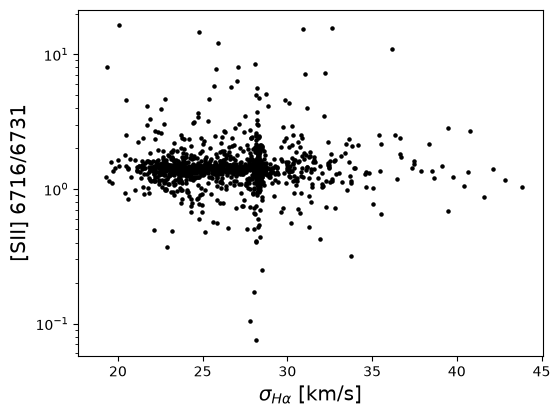

In [7]:
fig, ax = plt.subplots(figsize=(6,4.5))
snrcut = 10
mask_SN_Ha = tab_DAP['flux_pe_6562.85']/tab_DAP['e_flux_pe_6562.85'] > snrcut
ax.scatter((tab_DAP['sigma_kms_pek_6562.85'])[mask_SN_Ha],
           (tab_DAP['flux_[SII]_6716.44']/tab_DAP['flux_[SII]_6730.82'])[mask_SN_Ha],
           s=5, c='black')
ax.set_xlabel(r'$\sigma_{H\alpha}$ [km/s]', fontsize='x-large')
ax.set_ylabel(r'[SII] 6716/6731', fontsize='x-large')
ax.set_yscale('log')

## [N II]/Hα versus velocity dispersion

This diagnostic links a low-ionization line ratio to the kinematic width of Hα.  
It is useful to identify whether high-dispersion regions are also associated with enhanced low-ionization emission.

For the Helix, elevated `[N II]/Hα` values are expected near the ionization front and in denser outer structures, where [N II] becomes relatively strong compared to Hα.

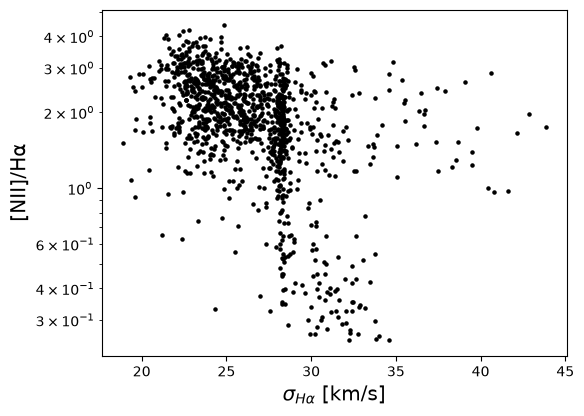

In [8]:
fig, ax = plt.subplots(figsize=(6,4.5))
snrcut = 10
mask_SN_Ha = tab_DAP['flux_pe_6562.85']/tab_DAP['e_flux_pe_6562.85'] > snrcut
ax.scatter((tab_DAP['sigma_kms_pek_6562.85'])[mask_SN_Ha],
           (tab_DAP['flux_pek_6583.45']/tab_DAP['flux_pek_6562.85'])[mask_SN_Ha],
           s=5, c='black')
ax.set_xlabel(r'$\sigma_{H\alpha}$ [km/s]', fontsize='x-large')
ax.set_ylabel(r'[NII]/Hα', fontsize='x-large')
ax.set_yscale('log')

## Function to generate a simple map from a single column

This function forms the backbone of the multi-panel plots.  Dots representing the fibers are colored by the column value (for example, the flux in a particular line).

In [9]:
def map_plot_DAP_ax(tab, ax=None, line='flux_Halpha_6562.85', title=None,
                    vmin=None, vmax=None, cmap='Spectral',
                    gamma=1.0, sf=1.0, xlab=True, ylab=True, f_scale=10):

    # By default, f_scale=10 converts units from 1e-16 erg/s/cm2/spx to 1e-15 erg/s/cm2/spx.
    
    X = tab['ra']
    Y = tab['dec']
    C = tab[line]/f_scale    
    if (title == None):
        title=line.replace("_"," ")
        title=line.replace("_"," ")

    norm = mpl_colors.PowerNorm(vmin=vmin,vmax=vmax,gamma=gamma)
    scat = ax.scatter(X, Y, s=10*sf, c=C, cmap=cmap, norm=norm, rasterized=True)

    if xlab:
        ax.set_xlabel('Ra [deg]', fontsize='x-large')
    if ylab:
        ax.set_ylabel('Dec [deg]', fontsize='x-large')
    ax.invert_xaxis()
    props = dict(boxstyle='square', facecolor='white', alpha=0.5)
    ax.text(0.05, 0.95, rf'{title}', ha='left', va='top', bbox=props, size='x-large', transform=ax.transAxes)

    return scat

## Hα kinematics: velocity and velocity dispersion

This figure reproduces one of the core physical results of the Helix analysis:
- the Hα velocity field,
- and the Hα velocity-dispersion field.

In the Helix paper, the velocity map shows a large-scale redshifted/blueshifted symmetry consistent with a slowly expanding, moderately inclined shell.  
The velocity-dispersion map is generally narrow, with somewhat broader profiles in the inner cavity and the brightest ring, consistent with thermal broadening plus modest unresolved turbulent motions.

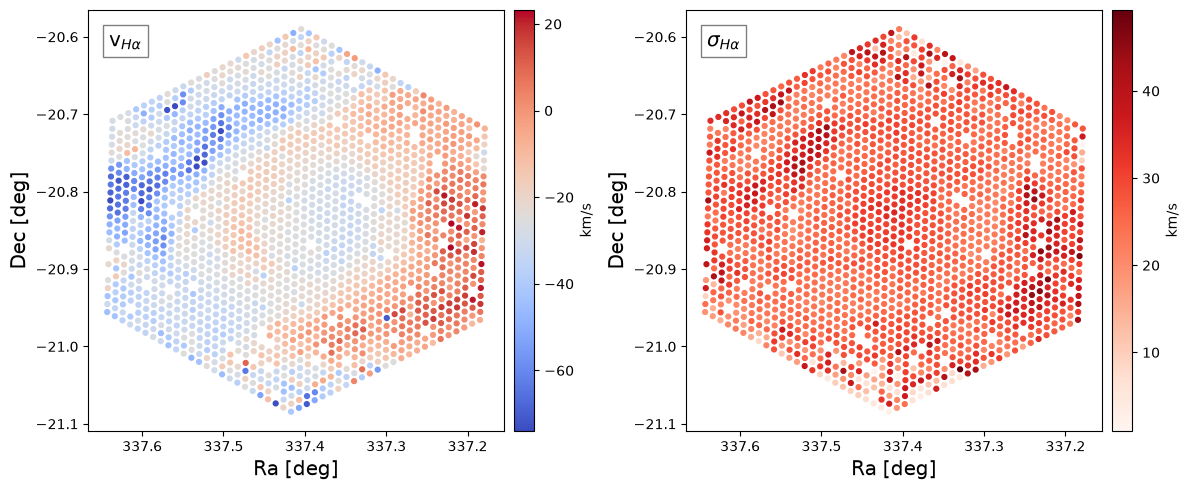

In [10]:
fig, axs = plt.subplots(1,2,figsize=(12,5))

# Halpha velocity map
scat = map_plot_DAP_ax(tab_DAP, ax=axs[0], line='vel_pek_6562.85',
                       title=r'v$_{H\alpha}$', cmap='coolwarm', 
                       xlab=True, ylab=True, sf=1.2, f_scale=1)
divider = make_axes_locatable(axs[0])
cax = divider.append_axes("right", size="5%", pad=0.1)
fig.colorbar(scat, cax=cax, label='km/s')

# Halpha dispersion map
scat = map_plot_DAP_ax(tab_DAP, ax=axs[1], line='sigma_kms_pek_6562.85', 
                       title=r'$\sigma_{H\alpha}$', cmap='Reds', 
                       xlab=True, ylab=True, sf=1.2, f_scale=1)
divider = make_axes_locatable(axs[1])
cax = divider.append_axes("right", size="5%", pad=0.1)
fig.colorbar(scat, cax=cax, label='km/s')

plt.tight_layout(w_pad=1)

## Comparison of Hα flux products

The left panel shows the spatial distribution of the Hα flux derived from the **non-parametric** DAP analysis, which is the most convenient product for mapping the nebular emission over the full field. The right panel compares the Hα flux measured with the non-parametric method against the value derived from the **second parametric fit** (`PEK`), which is optimized for strong lines after refinement of the stellar-continuum subtraction. Agreement between both measurements indicates that the line is robustly recovered, while deviations usually become more important in low-signal fibers or in regions affected by background residuals.

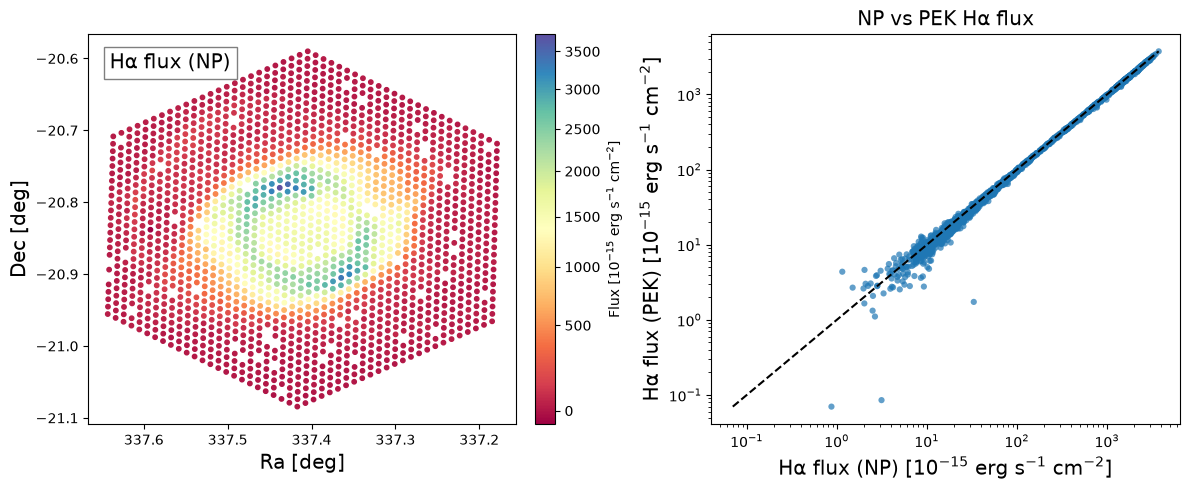

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

line_np = 'flux_Halpha_6562.85'
line_pek = 'flux_pek_6562.85'

# Left panel: Halpha flux map (NP measurement)

scat = map_plot_DAP_ax(tab_DAP, ax=axs[0], line=line_np, title=r'Hα flux (NP)',
                       cmap='Spectral', gamma=0.7, f_scale=10)

cb = fig.colorbar(scat, ax=axs[0], fraction=0.046, pad=0.04)
cb.set_label(r'Flux [$10^{-15}$ erg s$^{-1}$ cm$^{-2}$]')

# Right panel: NP vs PEK comparison (convert to 1e-15 unit)

Ha_np  = tab_DAP[line_np]/10
Ha_pek = tab_DAP[line_pek]/10

mask = (Ha_np > 0) & (Ha_pek > 0)

axs[1].scatter(Ha_np[mask], Ha_pek[mask], s=20, alpha=0.7, edgecolor='none')

if np.any(mask):
    lo = min(np.nanmin(Ha_np[mask]), np.nanmin(Ha_pek[mask]))
    hi = max(np.nanmax(Ha_np[mask]), np.nanmax(Ha_pek[mask]))
    axs[1].plot([lo, hi], [lo, hi], '--', color='black', lw=1.5)

axs[1].set_xlabel(r'Hα flux (NP) [$10^{-15}$ erg s$^{-1}$ cm$^{-2}$]', fontsize='x-large')
axs[1].set_ylabel(r'Hα flux (PEK) [$10^{-15}$ erg s$^{-1}$ cm$^{-2}$]', fontsize='x-large')
axs[1].set_title(r'NP vs PEK Hα flux', fontsize='x-large')
axs[1].set_xscale('log')
axs[1].set_yscale('log')

plt.tight_layout()
plt.show()

## Gallery of the brightest emission-line maps

This multi-panel figure displays the strongest lines in the field one by one.  
It is one of the most informative sections of the notebook because it lets you compare spatial morphology across ions and transitions.

In the Helix paper, the bright-line maps reveal:
- Balmer lines tracing the full ionized shell,
- [O III] emphasizing the high-excitation inner ring,
- [N II], [O II], and [S II] tracing the lower-ionization outer structures and ionization front.

In [12]:
def multiline_plot(tab, linelist=None, f_scale=10, 
                    vmin=None, vmax=None, cmap='gist_earth_r',
                    gamma=0.2, sf=2, NX=4, NY=4):

    for I0 in np.arange(0, len(linelist), NX*NY):
        fig, axs = plt.subplots(nrows=NY, ncols=NX, figsize=(5*NX, 5*NY))
    
        for I, ax in enumerate(np.ravel(axs)):
            I_now = I0 + I
            if (I_now >= len(linelist)):
                ax.set_yticks([])
                ax.set_xticks([])
                ax.set_axis_off()
            else:
                eline = linelist[I_now]
                title = eline.replace('flux_','')
                title = title.replace('_',' ')
                title = title.replace('alpha','$\\alpha$')
                title = title.replace('beta','$\\beta$')
                title = title.replace('gamma','$\\gamma$')    
                title = title.replace('delta','$\\delta$')
                title = title.replace('epsilon','$\\epsilon$')    
                xlab  = False
                ylab  = False
                if (I % NX) == 0:
                    ylab=True
                else:
                    ax.set_yticks([])
                if I >= (NX-1)*NY:
                    xlab=True
                else:
                    ax.set_xticks([])
                if vmax is None:
                    vmax = 1e4
            
                scat = map_plot_DAP_ax(tab, ax=ax, line=eline, title=title, cmap=cmap, 
                                       gamma=gamma, xlab=xlab, ylab=ylab, sf=sf, 
                                       f_scale=f_scale, vmin=vmin, vmax=vmax)
                ax.set_aspect('equal')
            
        plt.subplots_adjust(wspace=0,hspace=0)
        cbar = fig.colorbar(scat, ax=axs.ravel().tolist(), orientation='vertical')
        cbar.set_label('Flux Intensity [10$^{-15}$ erg/s/cm$^2$/spaxel]', size='x-large')
        plt.show()
        plt.close()

    return

Plotting 15 lines


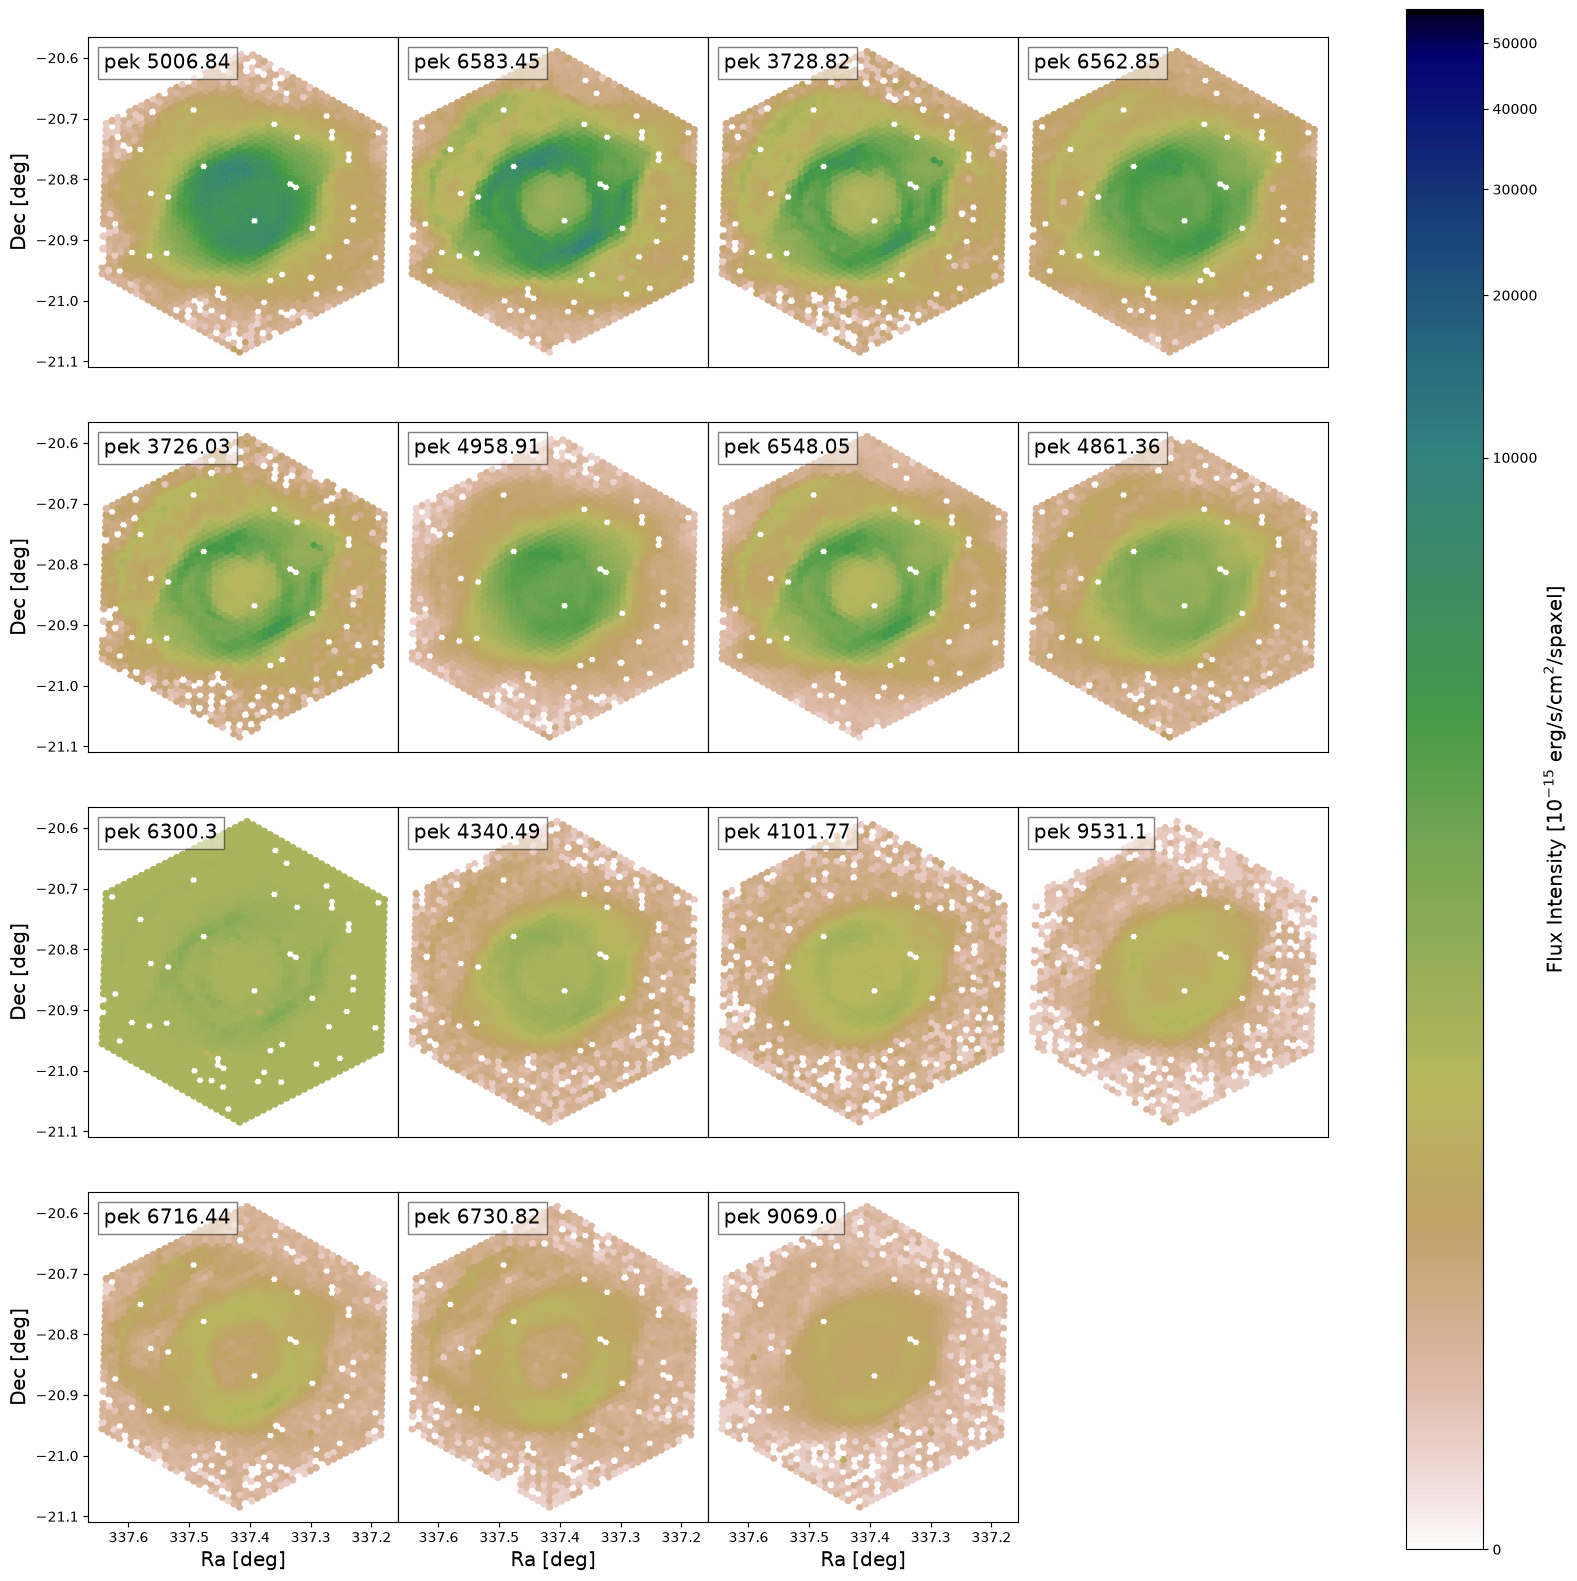

In [13]:
peklines = list(set(search_col(tab_DAP,'flux_pek')) - set(search_col(tab_DAP,'e_flux_pek')))
print('Plotting', len(peklines), 'lines')
maxval = [np.nanpercentile(tab_DAP[c],98) for c in peklines]
t_sort = Table([peklines, maxval], names=['label', 'maxval'])
t_sort.sort('maxval', reverse=True)
pek_sorted_label = (t_sort['label']).tolist()
multiline_plot(tab_DAP, linelist=pek_sorted_label, vmin=0, vmax=t_sort['maxval'][0])

Plotting 215 lines


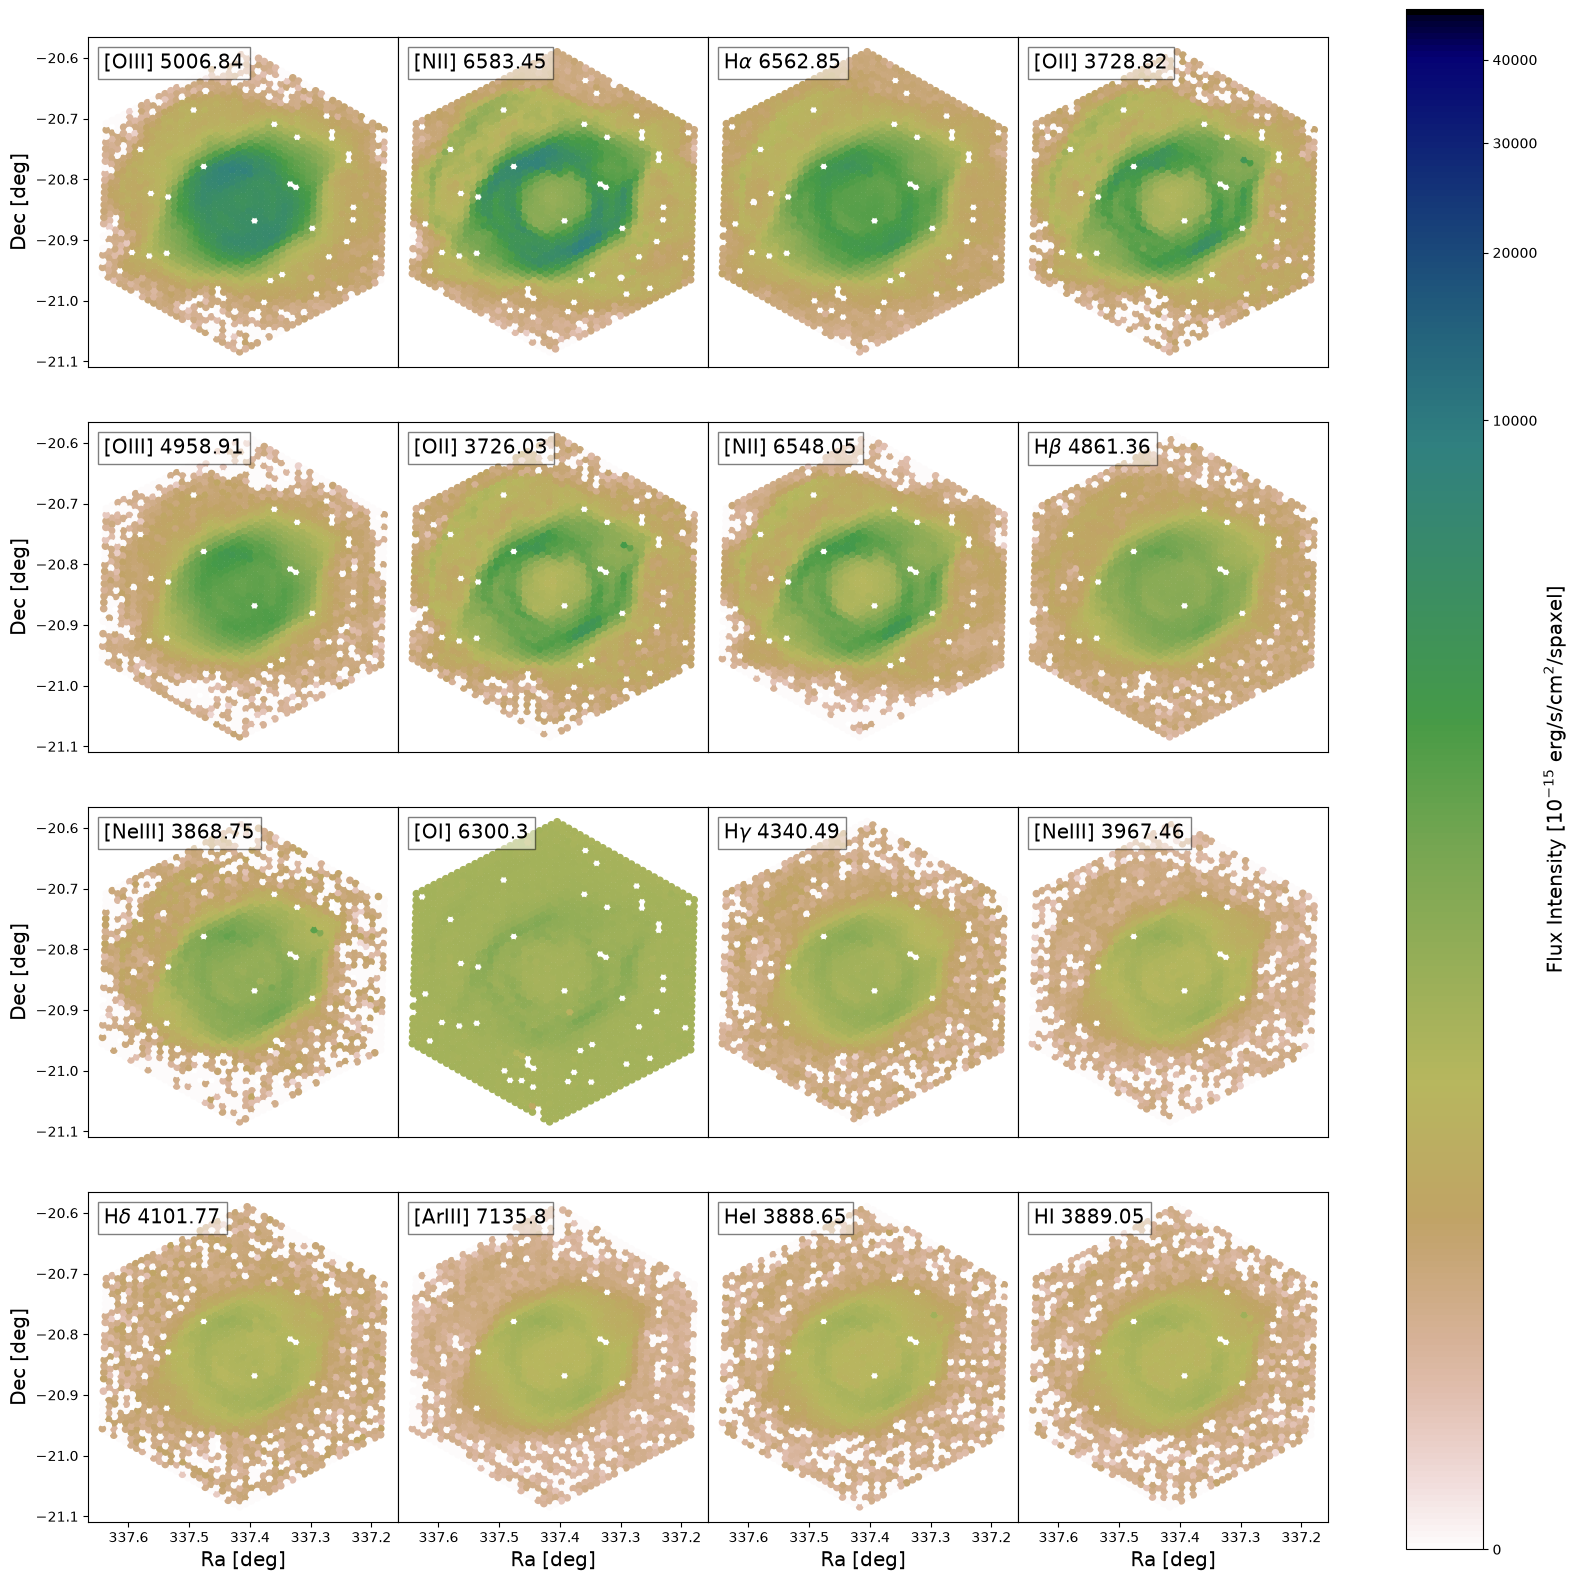

In [15]:
nplines = list(set(search_col(tab_DAP,'flux_')) - set(search_col(tab_DAP,'_pe')) 
               - set(search_col(tab_DAP,'st')) - set(search_col(tab_DAP,'e_flux_')))
print('Plotting', len(nplines), 'lines')
maxval = [np.nanpercentile(tab_DAP[c],95) for c in nplines]
t_sort = Table([nplines, maxval], names=['label', 'maxval'])
t_sort.sort('maxval', reverse=True)
np_sorted_label = (t_sort['label']).tolist()
multiline_plot(tab_DAP, linelist=np_sorted_label[:16], vmin=0, vmax=t_sort['maxval'][0])

## Function to generate an RGB map from three separate columns

This function converts three selected DAP columns into an RGB representation on the sky.
It is especially useful for quick visual exploration because it combines three physically different tracers into a single image.

For nebular data, these composite maps are often the fastest way to identify ionization stratification:
- a high-ionization line can be mapped to one color,
- Hα or another recombination line to another,
- and a low-ionization line to a third one.

In the Helix paper, this kind of comparison is central to showing how the compact high-ionization core, the bright [O III] ring, and the low-ionization outer structures are spatially separated.

In [16]:
def map_plot_DAP_rgb(tab_DAP,
                     rgb_key=('flux_pe_6583.45','flux_pe_6562.85','flux_pe_5006.84'),
                     rgb_scale=(1.0,1.0,1.0), titles=('r','g','b'),
                     figsize=5, vmin=0, vmax=0, gamma=1.0, ptsize=30):
    
    X = tab_DAP['ra'].value
    Y = tab_DAP['dec'].value
    R = tab_DAP[rgb_key[2]].value * rgb_scale[0]
    G = tab_DAP[rgb_key[1]].value * rgb_scale[1]
    B = tab_DAP[rgb_key[0]].value * rgb_scale[2]
    RGB = np.stack((R, G, B), axis=1)
    if (vmin==vmax):
        vmin=np.nanmin(RGB)
        vmax=np.nanmax(RGB)
    print(f'min/max:{vmin}/{vmax}')
    r = (R-vmin)/(vmax-vmin)
    g = (G-vmin)/(vmax-vmin)
    b = (B-vmin)/(vmax-vmin)

    r = np.ma.filled(r.clip(0,1), fill_value=0.0)
    g = np.ma.filled(g.clip(0,1), fill_value=0.0)
    b = np.ma.filled(b.clip(0,1), fill_value=0.0)
    r=r**gamma
    g=g**gamma
    b=b**gamma
    
    r = np.ma.compressed(r)
    g = np.ma.compressed(g)
    b = np.ma.compressed(b)   
    colors = np.stack((r, g, b), axis=1)

    fig, ax = plt.subplots(figsize=(figsize, figsize*0.95))
    ax.scatter(X, Y, color=colors, s=ptsize)
    ax.set_xlabel('R.A. [deg]', size='x-large')
    ax.set_ylabel('Dec [deg]', size='x-large')
    ax.invert_xaxis()
    ax.text(0.03, 0.97, rf'{titles[0]}', ha='left', va='top',color='tomato', 
            size='x-large', transform=ax.transAxes)
    ax.text(0.03, 0.92, rf'{titles[1]}', ha='left', va='top',color='forestgreen', 
            size='x-large', transform=ax.transAxes)
    ax.text(0.03, 0.87, rf'{titles[2]}', ha='left', va='top',color='steelblue', 
            size='x-large', transform=ax.transAxes)

    return colors

min/max:-1000/50000.0


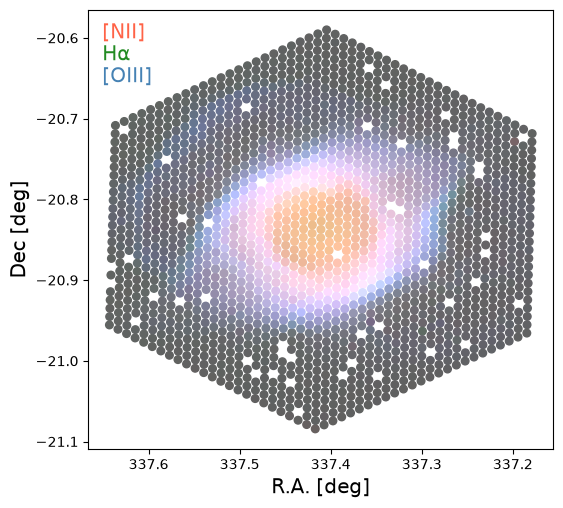

In [17]:
colors = map_plot_DAP_rgb(tab_DAP, 
                 rgb_key=('flux_pe_6583.45','flux_pe_6562.85','flux_pe_5006.84'),
                 rgb_scale = (1,1,1), vmin=-1000, vmax=50000.0,
                 titles=('[NII]','Hα','[OIII]'), 
                 figsize=6, gamma=0.25)